# Data Preprocessing and Feature Engineering

Turns the games.csv into `X_train`, `X_test`, `y_train`, `y_test` for predicting whether a game becomes a commercial hit using only what is on its store page at launch.

The notebook writes its outputs to `data/processed/` (gitignored so only appears after a run)

## Decisions for this preprocessing + FE:
| Decision | Choice |
| --- | --- |
| Label | hit = `Estimated owners` ≥ 100,000 |
| Population | games with owner data (not "0 - 0"), released 2015–2023 |
| Duplicates | one row per game name, keeping the earliest release |
| Split | by release date: train 2015–2021, test 2022–2023 |
| Leakage rule | only launch-day store-page information; 2026-snapshot fields (languages, achievements, screenshots, price) kept |
| Imbalance / scaling | data is handed over unscaled and unresampled, or ya'll can ask me (Semyon) to finish this too |


TOOD: maybe write more explanations of what I did here

## Steps:
1. Load the data
2. 2. 

## Setup/ config


In [1]:
# Imports, fail here instead of later
from pathlib import Path
import csv
import json
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_val_predict, cross_val_score
from sklearn.feature_selection import RFECV, chi2
from sklearn.metrics import average_precision_score

# CSV loading vars: find in or around .git, output into data inside git
CSV_CANDIDATES = [
    Path("../../games.csv"),  
    Path("../data/games.csv"),
    Path("data/games.csv"),
    Path("../games.csv"),
    Path("games.csv"),
]
OUT_DIR = Path("../data/processed")

# Visual components vars
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 60)

# Project vars 
HIT_THRESHOLD = 100_000
YEAR_MIN, YEAR_MAX = 2015, 2023
SPLIT = "date"
TEST_YEARS = (2022, 2023)
DEDUPE_NAMES = True
MIN_LABEL_COUNT = 50
RANDOM_STATE = 42


# All good if printed
print("pandas", pd.__version__)

pandas 3.0.3


## Step 1: Load the data and fix the header

The CSV header has 39 names, but every data row has 40 fields. It looks like this happened because the names `Discount` and `DLC count` were fused into one header entry: `DiscountDLC count`. 

So to not shift every column after `Price` by one (`About the game` would hold DLC counts), I did:
1. read only the header and the first data row with `csv.reader`, and confirm the problem affects anything (yea it did)
2. split the fused name in two
3. read the file with `pd.read_csv(path, names=header, skiprows=1)` param
4. 
Then every column is renamed to `snake_case``

In [2]:
# Find the data
def find_csv(candidates=CSV_CANDIDATES):
    for path in candidates:
        if path.exists():
            return path
    raise FileNotFoundError("games.csv not found")

CSV_PATH = find_csv()
print("Reading", CSV_PATH.resolve())

Reading C:\School\8th-semester-comprehensive\intro-to-machine-learning\project\games.csv


In [3]:
# Can be deleted bc it's a check:
# 39 header vs 40 field -> would it jumble

with open(CSV_PATH, encoding="utf-8", newline="") as f:
    reader = csv.reader(f)
    raw_header = next(reader)
    first_row = next(reader)

#print(f"Header names: {len(raw_header)}   fields in the first data row: {len(first_row)}")
#assert "DiscountDLC count" in raw_header and len(first_row) == len(raw_header) + 1, \
#    "The header problem is not the expected one. Inspect the file before going on."

header = raw_header.copy()
i = header.index("DiscountDLC count")
header[i:i + 1] = ["Discount", "DLC count"]
assert len(header) == len(first_row)

# Show the fields around the fix for the first game: Price, Discount, DLC count, About the game
pd.DataFrame({"column": header[i - 1:i + 3], "first game's value": first_row[i - 1:i + 3]})

,column,first game's value
0,Price,0.0
1,Discount,0
2,DLC count,0
3,About the game,


In [4]:
# Read the dataset
df = pd.read_csv(CSV_PATH, names=header, skiprows=1, low_memory=False)
print(f"{df.shape[0]:,} rows x {df.shape[1]} columns")

# If the header were still misaligned, these numeric columns would hold text
for col in ["Price", "Discount", "DLC count", "Peak CCU"]:
    assert pd.api.types.is_numeric_dtype(df[col]), f"{col} is not numeric: the columns are shifted"
assert df["Estimated owners"].str.contains(" - ").all(), "Estimated owners should look like '20000 - 50000'"
print("Column alignment checks passed.")

125,855 rows x 40 columns
Column alignment checks passed.


### Rename columns to snake_case

`Release date` -> `release_date`, `Peak CCU` -> `peak_ccu`). `AppID` -> `app_id`. 

Also a little assert check like last time

In [5]:
def to_snake(name):
    name = name.replace("AppID", "App ID")              # keep "app" and "id" as separate words
    name = re.sub(r"[^0-9a-zA-Z]+", "_", name.strip())  # spaces and punctuation -> "_"
    return name.strip("_").lower()

rename_map = {col: to_snake(col) for col in df.columns}
assert len(set(rename_map.values())) == len(rename_map), "this didn't work"
df = df.rename(columns=rename_map)

pd.DataFrame({"original": list(rename_map), "renamed": list(rename_map.values())})

,original,renamed
0,AppID,app_id
1,Name,name
2,Release date,release_date
3,Estimated owners,estimated_owners
4,Peak CCU,peak_ccu
5,Required age,required_age
6,Price,price
7,Discount,discount
8,DLC count,dlc_count
9,About the game,about_the_game


Expected: 125,855 rows x 40 columns, and the raw header had 39 names.

In [6]:
assert len(raw_header) == 39, len(raw_header)
assert df.shape == (125_855, 40), df.shape
print(f"Everything worked: {df.shape[0]:,} rows x {df.shape[1]} columns (raw header had {len(raw_header)} names).")

overview = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing": df.isna().sum(),
    "missing_%": (df.isna().mean() * 100).round(1),
    "n_unique": df.nunique(),
})
overview

Everything worked: 125,855 rows x 40 columns (raw header had 39 names).


,dtype,missing,missing_%,n_unique
app_id,int64,0,0.0,125855
name,str,1,0.0,124644
release_date,str,0,0.0,5141
estimated_owners,str,0,0.0,14
peak_ccu,int64,0,0.0,1110
required_age,int64,0,0.0,15
price,float64,0,0.0,953
discount,int64,0,0.0,88
dlc_count,int64,0,0.0,117
about_the_game,str,8462,6.7,116776


In [7]:
df.sample(3, random_state=RANDOM_STATE)

,app_id,name,release_date,estimated_owners,peak_ccu,required_age,price,discount,dlc_count,about_the_game,supported_languages,full_audio_languages,reviews,header_image,website,support_url,support_email,windows,mac,linux,metacritic_score,metacritic_url,user_score,positive,negative,score_rank,achievements,recommendations,notes,average_playtime_forever,average_playtime_two_weeks,median_playtime_forever,median_playtime_two_weeks,developers,publishers,categories,genres,tags,screenshots,movies
127,3400080,Fantasy Soul Revenge,"Dec 28, 2024",0 - 20000,0,0,0.69,0,0,Fantasy Soul Revenge - Explore Your Fighting Skills Beat...,"['English', 'French', 'Italian', 'German', 'Spanish - Sp...",[],NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN,NaN,nitin.javapro@gmail.com,True,False,False,0,NaN,0,4,2,NaN,0,0,NaN,0,0,0,0,Nitx Games,Nitx Games,"Single-player,Family Sharing","Action,Casual,Indie,Simulation,Strategy","Side Scroller,Action,Beat 'em up,2D Fighter,Arcade,Actio...",https://shared.akamai.steamstatic.com/store_item_assets/...,NaN
67814,2554950,Raioh,"Oct 6, 2023",0 - 20000,0,0,3.49,50,0,Raioh is a retro style shot and bomb style vertical scro...,['English'],[],NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN,NaN,ontake44@gmail.com,True,False,False,0,NaN,0,17,0,NaN,0,0,NaN,0,0,0,0,Ontake Workshop,Ontake Workshop,"Single-player,Partial Controller Support,Family Sharing",Action,"Action,Shooter,Shoot 'Em Up,Singleplayer,2D,Pixel Graphi...",https://shared.akamai.steamstatic.com/store_item_assets/...,NaN
29650,4025190,Ten Tek,"Oct 18, 2025",0 - 0,0,0,1.59,0,0,TenTek is an atmospheric mystical game where you take on...,"['English', 'Russian']","['English', 'Russian']",NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN,NaN,lgcompanymonitors@gmail.com,True,False,False,0,NaN,0,0,0,NaN,0,118,The game contains scenes of full nudity and explicit sex...,0,0,0,0,Inspite,Inspite,"Single-player,Family Sharing","Indie,Simulation",NaN,https://shared.akamai.steamstatic.com/store_item_assets/...,NaN


## Step 2: Build the label

`estimated_owners` is SteamSpy's estimate of how many people own the game, given as a range like `"20000 - 50000"`.
Parsing it gives two numbers: `owners_low` and `owners_high`.

hit = 1 when `owners_low` >= 100,000 (`HIT_THRESHOLD` is var name in setup), else 0.
- The lower end means a game is a hit only if even SteamSpy's lowest estimate reaches 100k.
- 100,000 is also an edge of SteamSpy's ranges (`50,000 - 100,000` then `100,000 - 200,000`), so no range is partial hit.

`"0 - 0"` doesn't mean zero owners: SteamSpy has no data for that game. These are dropped later, set as `hit`=0 here for now

`estimated_owners`, `owners_low` and `owners_high` are the answer, drop them from the features later. These shouldn't be in training.

In [8]:
# Parse "20000 - 50000" -> 20000, 50000
bounds = df["estimated_owners"].str.extract(r"^\s*(\d+)\s*-\s*(\d+)\s*$") # I hate regex
df["owners_low"] = bounds[0].astype("int64")
df["owners_high"] = bounds[1].astype("int64")

# Check it works
assert bounds.notna().all().all(), "REGEX DIDN'T WORK"
assert (df["owners_low"] <= df["owners_high"]).all()

# Label is set here
df["hit"] = (df["owners_low"] >= HIT_THRESHOLD).astype("int64")

In [9]:
# Every SteamSpy range, smallest first, and what label it gets
owner_ranges = df.groupby(["owners_low", "owners_high"]).size().rename("games").reset_index()
owner_ranges["label"] = np.select(
    [owner_ranges["owners_high"].eq(0), owner_ranges["owners_low"].ge(HIT_THRESHOLD)],
    ["no data", "hit"],
    default="not hit",
)
owner_ranges["% of all games"] = (owner_ranges["games"] / len(df) * 100)
owner_ranges.insert(0, "range", owner_ranges["owners_low"].map("{:,}".format) + " - " + owner_ranges["owners_high"].map("{:,}".format))
owner_ranges.drop(columns=["owners_low", "owners_high"])

,range,games,label,% of all games
0,0 - 0,24579,no data,19.529617
1,"0 - 20,000",75705,not hit,60.152557
2,"20,000 - 50,000",11397,not hit,9.055659
3,"50,000 - 100,000",5355,not hit,4.254897
4,"100,000 - 200,000",3454,hit,2.744428
5,"200,000 - 500,000",2856,hit,2.269278
6,"500,000 - 1,000,000",1155,hit,0.917723
7,"1,000,000 - 2,000,000",729,hit,0.579238
8,"2,000,000 - 5,000,000",405,hit,0.321799
9,"5,000,000 - 10,000,000",125,hit,0.099321


Expected: 24,579 `"0 - 0"` rows | 101,276* rows with owner data, 8,819 of them hits (~8.7%)

In [10]:
no_data = df["owners_high"].eq(0)
with_data = df.loc[~no_data]

# Stop here if code no work :(
assert no_data.sum() == 24_579
assert len(with_data) == 101_276 and with_data["hit"].sum() == 8_819


print(f'"0 - 0": {no_data.sum()} rows ({no_data.mean()})')
print(f"With owner data: {len(with_data):,} rows, {with_data['hit'].sum()} hits ({with_data['hit'].mean()})")

"0 - 0": 24579 rows (0.1952961741686862)
With owner data: 101,276 rows, 8819 hits (0.08707887357320589)


## Step 3: Filter rows

Two filters decide which games get modeled:
1. Drop the `"0 - 0"` rows
2. Keep games released 2015 to 2023 (`YEAR_MIN`, `YEAR_MAX`). The hit-rate-by-year table below shows why:
   - Before 2015 Steam was curated, so most listed games sold a lot by this point.
   - From 2024 on, games haven't had time to collect owners (the data is a 2026 snapshot). Many of these games would count as "not hit" just because they're new

`release_date` is text like `"Jul 10, 2020"`, so it's parsed with `pd.to_datetime(format="mixed")`. A bad date crashes here watch out.

In [11]:
# Drop "0 - 0"
n_before = len(df)
df = df.loc[df["owners_high"] > 0].copy()
print(f'Dropped {n_before - len(df)} rows -> {len(df)} games left')

Dropped 24579 rows -> 101276 games left


In [12]:
# 2. Text -> datetime
df["release_date"] = pd.to_datetime(df["release_date"], format="mixed")
df["release_year"] = df["release_date"].dt.year

assert df["release_date"].notna().all(), "FAIL"
print("Release dates go from", df["release_date"].min().date(), "to", df["release_date"].max().date())

Release dates go from 1997-06-30 to 2026-03-01


In [13]:
# Show how early games have few number of games and are very high hit percent
by_year = df.groupby("release_year")["hit"].agg(games="size", hits="sum", hit_pct="mean")
by_year["hit_pct"] = (by_year["hit_pct"] * 100)
by_year["kept"] = by_year.index.to_series().between(YEAR_MIN, YEAR_MAX)
by_year

,games,hits,hit_pct,kept
release_year,,,,
1997,2,2,100.000000,False
1998,1,1,100.000000,False
1999,2,2,100.000000,False
2000,2,2,100.000000,False
2001,4,4,100.000000,False
2002,1,1,100.000000,False
2003,3,2,66.666667,False
2004,6,6,100.000000,False
2005,7,4,57.142857,False


In [14]:
# 3. Keep only the release window
too_early = df["release_year"] < YEAR_MIN
too_late = df["release_year"] > YEAR_MAX

print(f"Dropping {too_early.sum()} games released before {YEAR_MIN} and {too_late.sum()} after {YEAR_MAX}")
df = df.loc[~too_early & ~too_late].copy()
print(f"{len(df)} games left")

Dropping 3451 games released before 2015 and 30528 after 2023
67297 games left


Expected (for 2015-2023): 67,297 games, 6,187 of them hits (~9.2%)

In [15]:
assert df["release_year"].between(YEAR_MIN, YEAR_MAX).all()
assert len(df) == 67_297, len(df)
assert df["hit"].sum() == 6_187, df["hit"].sum()

print(f"{len(df)} games, {df['hit'].sum()} hits ({df['hit'].mean()})")

67297 games, 6187 hits (0.09193574750731831)


## Step 4: Drop irrelevant and leaky columns

Leakage rule: a column can only be a feature if it was on the store page on launch day. Anything that counts sales, players or reviews is basically the answer.

- `DROP_LOG` = every dropped column, with a group and a reason
- `KEEP_LOG` = every kept column and what it's for
- an assert checks that every column is in exactly one of the two, so nothing gets kept or dropped by accident

Groups: label (the answer itself), post-sale (only exists after people buy and play), after launch (added or changed after release), empty/constant, id/media, irrelevant.

Steam Trading Cards isn't a column, it's one label inside `categories`. Valve only gives trading cards to games after
they sell, so it leaks too. It's removed in step 10 when categories become 0/1 columns (`LEAKY_CATEGORIES`).

Gray area: price, achievements, languages and screenshots come from the 2026 snapshot and might have changed since
launch. Kept (team decision), mention at the defense.

In [16]:
# (group, reason)
DROP_LOG = {
    # The answer itself
    "estimated_owners": ("label", "hit is built from it"),
    "owners_low": ("label", "hit is built from it"),
    "owners_high": ("label", "hit is built from it"),
    # Only exist after people buy and play the game
    "peak_ccu": ("post-sale", "peak concurrent players"),
    "positive": ("post-sale", "positive user reviews"),
    "negative": ("post-sale", "negative user reviews"),
    "recommendations": ("post-sale", "user recommendations"),
    "metacritic_score": ("post-sale", "critic score, comes out after release"),
    "metacritic_url": ("post-sale", "link to the critic score"),
    "user_score": ("post-sale", "user score (almost always 0 = no score)"),
    "score_rank": ("post-sale", "rank from user reviews, ~100% empty"),
    "average_playtime_forever": ("post-sale", "playtime of owners"),
    "average_playtime_two_weeks": ("post-sale", "playtime of owners"),
    "median_playtime_forever": ("post-sale", "playtime of owners"),
    "median_playtime_two_weeks": ("post-sale", "playtime of owners"),
    # Added or changed after launch
    "tags": ("after launch", "added by players"),
    "reviews": ("after launch", "press quotes, added once reviews are out"),
    "dlc_count": ("after launch", "DLCs released since launch (2026 count)"),
    "discount": ("after launch", "discount on the 2026 scrape day"),
    # No information
    "movies": ("empty", "100% missing"),
    "windows": ("constant", "only 26 games don't support Windows"),
    # IDs and media
    "header_image": ("id/media", "image URL"),
    # Free text with almost no signal
    "notes": ("irrelevant", "content warnings: ~no signal, required_age covers age-gating"),
}
# Leaky labels inside categories
LEAKY_CATEGORIES = ["Steam Trading Cards"]

In [17]:
KEEP_LOG = {
    "hit": "the label (y)",
    "name": "duplicate check, outlier examples (dropped in step 16)",
    "app_id": "duplicate tie-break (smallest = base game), dropped in step 5",
    "release_date": "month/weekday, studio history dropped after",
    "release_year": "feature, and the step 7 split key",
    "price": "feature (2026 snapshot, gray area)",
    "required_age": "feature (one-hot)",
    "achievements": "feature",
    "mac": "feature (0/1)",
    "linux": "feature (0/1)",
    "supported_languages": "count, multi-hot",
    "full_audio_languages": "count of voiced languages",
    "genres": "count, multi-hot",
    "categories": "count, multi-hot (minus LEAKY_CATEGORIES)",
    "developers": "self_published flag, studio history",
    "publishers": "self_published flag, studio history",
    "about_the_game": "description length, TF-IDF",
    "website": "has_website flag",
    "support_url": "has_support_url flag",
    "support_email": "has_support_email flag",
    "screenshots": "screenshot count",
}

In [18]:
# How well this column separates hits: 0.5 = no signal, 1.0 = perfect
# Below 0.5 = same signal reversed (older games have smaller IDs and more hits)
# Only for numeric columns with nothing missing
def auc_vs_hit(col):
    s = df[col]
    if not pd.api.types.is_numeric_dtype(s) or s.isna().any() or s.nunique() < 2:
        return np.nan
    return roc_auc_score(df["hit"], s.astype(float))

# Evidence for the numeric drops: post-sale columns are 0.84-0.94 which is like nearly the answer
drop_table = pd.DataFrame(DROP_LOG, index=["group", "reason"]).T
drop_table["missing_%"] = (df[list(DROP_LOG)].isna().mean() * 100)
drop_table["auc_vs_hit"] = [round(auc_vs_hit(col), 3) for col in DROP_LOG]
drop_table

,group,reason,missing_%,auc_vs_hit
estimated_owners,label,hit is built from it,0.000000,NaN
owners_low,label,hit is built from it,0.000000,1.000
owners_high,label,hit is built from it,0.000000,1.000
peak_ccu,post-sale,peak concurrent players,0.000000,0.846
positive,post-sale,positive user reviews,0.000000,0.937
negative,post-sale,negative user reviews,0.000000,0.939
recommendations,post-sale,user recommendations,0.000000,0.836
metacritic_score,post-sale,"critic score, comes out after release",0.000000,0.607
metacritic_url,post-sale,link to the critic score,96.305927,NaN
user_score,post-sale,user score (almost always 0 = no score),0.000000,0.500


In [19]:
# Evidence for the text drops: compare hit rates with and without
checks = {
    "has tags": df["tags"].notna(),
    "has press reviews": df["reviews"].notna(),
    "has a Metacritic page": df["metacritic_url"].notna(),
    "has Steam Trading Cards": df["categories"].str.contains("Steam Trading Cards", regex=False, na=False),
    "has content notes": df["notes"].notna(),
}
pd.DataFrame({
    "games": {name: mask.sum() for name, mask in checks.items()},
    "hit_%_with": {name: round(df.loc[mask, "hit"].mean() * 100, 1) for name, mask in checks.items()},
    "hit_%_without": {name: round(df.loc[~mask, "hit"].mean() * 100, 1) for name, mask in checks.items()},
})

,games,hit_%_with,hit_%_without
has tags,61394,10.1,0.0
has press reviews,8515,23.1,7.2
has a Metacritic page,2486,57.2,7.4
has Steam Trading Cards,8962,32.4,5.6
has content notes,11946,9.7,9.1


In [20]:
# "Empty" and "constant" checks
print("windows:", df["windows"].value_counts().to_dict())
print("movies missing:", df["movies"].isna().mean())

assert (~df["windows"]).sum() == 26
assert df["movies"].isna().all()

windows: {True: 67271, False: 26}
movies missing: 1.0


In [21]:
# Every column has to be in exactly one of the two dicts
not_listed = set(df.columns) - set(DROP_LOG) - set(KEEP_LOG)
listed_twice = set(DROP_LOG) & set(KEEP_LOG)
not_a_column = (set(DROP_LOG) | set(KEEP_LOG)) - set(df.columns)

assert not not_listed and not listed_twice and not not_a_column, (not_listed, listed_twice, not_a_column)

n_cols = df.shape[1]
df = df.drop(columns=list(DROP_LOG))
print(f"Dropped {n_cols - df.shape[1]} columns -> {df.shape[1]} left")

Dropped 23 columns -> 21 left


Expected: 67,297 rows x 21 columns, nothing from `DROP_LOG` left

In [22]:
assert df.shape == (67_297, 21), df.shape
assert not set(DROP_LOG) & set(df.columns)

print(f"{df.shape[0]} rows x {df.shape[1]} columns")
pd.DataFrame({"dtype": df.dtypes.astype(str), "used_for": pd.Series(KEEP_LOG).reindex(df.columns)})

67297 rows x 21 columns


,dtype,used_for
app_id,int64,"duplicate tie-break (smallest = base game), dropped in s..."
name,str,"duplicate check, outlier examples (dropped in step 16)"
release_date,datetime64[us],"month/weekday, studio history dropped after"
required_age,int64,feature (one-hot)
price,float64,"feature (2026 snapshot, gray area)"
about_the_game,str,"description length, TF-IDF"
supported_languages,str,"count, multi-hot"
full_audio_languages,str,count of voiced languages
website,str,has_website flag
support_url,str,has_support_url flag


## Step 5: Duplicates

Three checks:
1. Exact duplicate rows: expect 0
2. Duplicate AppIDs: expect 0 (every Steam listing has its own ID)
3. The same game listed more than once

A name alone is a bad key. In 2015-2023, 356 names repeat and 338 of them are different games by different developers that just share a title (see the feature-engineering spike). So the key is name + developers.

Which row to keep: the earliest release, and if they tie on date, the smallest AppID, which is the base game, Keeping a sub-package would label a huge hit as a non-hit. The same game in train and test lets the model just remember it, and the sub-packages are basically wrong labels.

In [23]:
print("duplicate rows:", df.duplicated().sum())
print("duplicate app_ids:", df["app_id"].duplicated().sum())
print("duplicate rows if you ignore app_id:", df.drop(columns="app_id").duplicated().sum())
assert df.duplicated().sum() == 0
assert df["app_id"].duplicated().sum() == 0

duplicate rows: 0
duplicate app_ids: 0
duplicate rows if you ignore app_id: 32


In [24]:
# compare the two keys
DEDUPE_KEY = ["name", "developers"]
def dup_summary(key):
    in_group = df.duplicated(subset=key, keep=False)   # every row of a repeated group
    groups = df[in_group].groupby(key, dropna=False)["release_year"]
    return {
        "groups": groups.ngroups,
        "rows_dropped": df.duplicated(subset=key).sum(),
        "groups_in_train_and_test": ((groups.min() < TEST_YEARS[0]) & (groups.max() >= TEST_YEARS[0])).sum(),
    }

same_name = df[df.duplicated(subset="name", keep=False)]
n_diff_dev = same_name.groupby("name")["developers"].nunique(dropna=False).gt(1).sum()
print(f"{same_name['name'].nunique()} repeated names, {n_diff_dev} of them by different developers (= different games)")

pd.DataFrame({"name only": dup_summary(["name"]), "name + developers": dup_summary(DEDUPE_KEY)})

356 repeated names, 338 of them by different developers (= different games)


,name only,name + developers
groups,356,18
rows_dropped,428,46
groups_in_train_and_test,156,1


In [25]:
# The  real duplicate groups
dups = df[df.duplicated(subset=DEDUPE_KEY, keep=False)]
dups.groupby("name").agg(
    rows=("app_id", "size"),
    release_dates=("release_date", "nunique"),
    smallest_app_id=("app_id", "min"),
    hit_rows=("hit", "sum"),
).sort_values("rows", ascending=False)

,rows,release_dates,smallest_app_id,hit_rows
name,,,,
Shadow of the Tomb Raider: Definitive Edition,20,1,750920,1
Tom Clancy's Rainbow Six® Siege X,5,1,359550,1
Train Simulator Classic,5,1,24010,1
EA SPORTS FC™ 24,4,1,2195250,1
Gear Up,3,1,214420,1
Call of Duty®: Black Ops III,3,1,311210,1
Call of Duty®: Modern Warfare® II,2,1,1962660,0
EA SPORTS™ FIFA 23,2,1,1811260,1
Call of Duty®: WWII,2,1,476600,2


In [26]:
# Keep one row per game: earliest release first, same day -> smallest AppID (= base game)
if DEDUPE_NAMES:
    n_before = len(df)
    df = (df.sort_values(["release_date", "app_id"])
            .drop_duplicates(subset=DEDUPE_KEY, keep="first")
            .sort_index())   # back to the original row order
    print(f"Dropped {n_before - len(df)} duplicate listings -> {len(df)} games left")

Dropped 46 duplicate listings -> 67251 games left


In [27]:
# app_id was only kept for the tie-break
print("app_id AUC vs hit:", round(auc_vs_hit("app_id"), 3))

DROP_LOG["app_id"] = ("id/media", "Steam's ID number")
KEEP_LOG.pop("app_id", None)
df = df.drop(columns="app_id")

app_id AUC vs hit: 0.298


Expected: 67,251 games (46 duplicate listings dropped), 6,186 hits (~9.2%), 20 columns, no repeated name + developers

In [28]:
assert not df.duplicated(subset=DEDUPE_KEY).any()
assert df.shape == (67_251, 20), df.shape
assert df["hit"].sum() == 6_186, df["hit"].sum()

print(f"{len(df)} games, {df['hit'].sum()} hits ({df['hit'].mean()})")

67251 games, 6186 hits (0.09198376232323682)


## Step 6: Row-by-row features

Every feature here is computed from one game's own row.

- Counts: genres, categories, supported languages, voiced languages, screenshots, description length
- Flags (0/1): is_free, has_website, has_support_url, has_support_email, self_published, has_english, mac, linux
- Dates: month, weekday, is_weekend 
- Other: price, achievements, languages, voiced languages, screenshots, description length.

Some notes:
- If a game's genres are missing, its genre count is unknown, not 0. Step 8 fills these with a median learned on the train rows only, plus an "is missing" flag.
- Hidden missing: `supported_languages = "[]"` means unknown, since every game has at least one language. But `full_audio_languages = "[]"` really means no voice-over, so that one is a real 0.
- Steam Trading Cards isn't counted in `n_categories`.

`FEATURES` records every new column with its family and meaning. It becomes the data dictionary for the modelers.

In [29]:
FEATURES = {}

# Parse the list columns once
supported = df["supported_languages"].str.findall(r"'([^']*)'")  # "['English', 'German']" -> ["English", "German"]
voiced = df["full_audio_languages"].str.findall(r"'([^']*)'") # Same asa bove
no_languages = df["supported_languages"].eq("[]")    # hidden missing
categories = df["categories"].str.split(",")            # NaN stays NaN
n_leaky = categories.apply(lambda cats: sum(c in LEAKY_CATEGORIES for c in cats) if isinstance(cats, list) else np.nan)

# Counts (NaN when the source is missing)
df["n_genres"] = df["genres"].str.split(",").str.len()
df["n_categories"] = categories.str.len() - n_leaky
df["n_languages"] = supported.str.len().where(~no_languages)
df["n_voiced_languages"] = voiced.str.len() # "[]" = no voice-over = real 0
df["n_screenshots"] = df["screenshots"].str.count(",") + 1
df["description_length"] = df["about_the_game"].str.len()

FEATURES.update({
    "n_genres": ("count", "number of genres"),
    "n_categories": ("count", "number of store categories, not counting LEAKY_CATEGORIES"),
    "n_languages": ("count", "number of supported languages (NaN if the list is empty)"),
    "n_voiced_languages": ("count", "number of languages with full audio"),
    "n_screenshots": ("count", "number of store screenshots (2026 snapshot)"),
    "description_length": ("count", "characters in 'About the game'"),
})

In [30]:
# Flags
def self_published(devs, pubs):
    # 1 if any developer is also a publisher. NaN if either list is missing
    if not isinstance(devs, list) or not isinstance(pubs, list):
        return np.nan
    return float(bool({d.strip() for d in devs} & {p.strip() for p in pubs}))

df["self_published"] = [self_published(d, p) for d, p in zip(df["developers"].str.split(","), df["publishers"].str.split(","))]
df["is_free"] = df["price"].eq(0).astype(int)
df["has_website"] = df["website"].notna().astype(int)
df["has_support_url"] = df["support_url"].notna().astype(int)
df["has_support_email"] = df["support_email"].notna().astype(int)
df["has_english"] = supported.apply(lambda langs: "English" in langs).astype(float).where(~no_languages)
df["mac"] = df["mac"].astype(int)
df["linux"] = df["linux"].astype(int)

FEATURES.update({
    "self_published": ("flag", "a developer is also the publisher"),
    "is_free": ("flag", "price is 0"),
    "has_website": ("flag", "store page lists a website"),
    "has_support_url": ("flag", "store page lists a support URL"),
    "has_support_email": ("flag", "store page lists a support email"),
    "has_english": ("flag", "English is a supported language"),
    "mac": ("flag", "runs on Mac"),
    "linux": ("flag", "runs on Linux"),
})

In [31]:
# Dates
df["release_month"] = df["release_date"].dt.month
df["release_weekday"] = df["release_date"].dt.weekday   # 0 = Monday, 6 = Sunday
df["is_weekend"] = df["release_weekday"].ge(5).astype(int)

FEATURES.update({
    "release_year": ("date", "release year"),
    "release_month": ("date", "release month 1-12"),
    "release_weekday": ("date", "release weekday, 0 = Monday"),
    "is_weekend": ("date", "released on a Saturday or Sunday"),
})

df.groupby("release_weekday")["hit"].mean().mul(100).rename("hit_%").to_frame().T

release_weekday,0,1,2,3,4,5,6
hit_%,8.478418,11.498321,9.207689,11.511798,7.738056,3.602967,3.705062


In [32]:
# log1p on the skewed counts/amounts. log1p(0) = 0, so free games and 0 achievements are fine.
LOG_COLS = ["price", "achievements", "n_languages", "n_voiced_languages", "n_screenshots", "description_length"]

for col in LOG_COLS:
    df[f"log_{col}"] = np.log1p(df[col])
    FEATURES[f"log_{col}"] = ("log", f"log1p of {col}")

skew_cols = LOG_COLS + ["n_genres", "n_categories"]
pd.DataFrame({
    "skew_raw": df[skew_cols].skew().round(2),
    "skew_after_log1p": pd.Series({col: df[f"log_{col}"].skew() for col in LOG_COLS}),
})

,skew_raw,skew_after_log1p
achievements,24.92,0.337576
description_length,15.13,-0.197576
n_categories,1.88,NaN
n_genres,0.85,NaN
n_languages,7.32,1.669025
n_screenshots,4.94,1.120513
n_voiced_languages,10.43,2.707192
price,31.31,0.442740


In [33]:
# How much signal each new feature has on its own
def auc_known(col):
    known = df[col].notna()
    return roc_auc_score(df.loc[known, "hit"], df.loc[known, col])

new_cols = list(FEATURES)
pd.DataFrame({
    "family": pd.Series({col: FEATURES[col][0] for col in new_cols}),
    "missing": df[new_cols].isna().sum(),
    "mean": df[new_cols].mean(),
    "auc_vs_hit": pd.Series({col: auc_known(col) for col in new_cols}),
})

,family,missing,mean,auc_vs_hit
n_genres,count,93,2.858319,0.521569
n_categories,count,635,4.328224,0.688779
n_languages,count,47,4.487679,0.698477
n_voiced_languages,count,0,1.674786,0.613510
n_screenshots,count,38,8.938732,0.632625
description_length,count,86,1264.856145,0.635317
self_published,flag,374,0.747806,0.418448
is_free,flag,0,0.119270,0.546662
has_website,flag,0,0.486996,0.623059
has_support_url,flag,0,0.513122,0.589801


In [34]:
# Raw columns that are now fully CONSUMED MUAHAHAHAHA by a feature
CONSUMED = {
    "website": "has_website",
    "support_url": "has_support_url",
    "support_email": "has_support_email",
    "screenshots": "n_screenshots",
    "full_audio_languages": "n_voiced_languages",
}
for col, feature in CONSUMED.items():
    DROP_LOG[col] = ("turned into features", f"replaced by {feature}")
    KEEP_LOG.pop(col, None)

df = df.drop(columns=list(CONSUMED))
print(f"{df.shape[0]} rows x {df.shape[1]} columns")

67251 rows x 36 columns


Expected: 67,251 rows x 36 columns (20 - 5 replaced + 21 new). A count is NaN exactly where its source is missing,
flags are only 0/1 (or NaN where unknown), and no count is negative.

In [35]:
assert df.shape == (67_251, 36), df.shape

# NaN only where the source was missing
assert df["n_genres"].isna().sum() == df["genres"].isna().sum()
assert df["n_categories"].isna().sum() == df["categories"].isna().sum()
assert df["description_length"].isna().sum() == df["about_the_game"].isna().sum()
assert df["self_published"].isna().sum() == (df["developers"].isna() | df["publishers"].isna()).sum()
assert df["n_languages"].isna().sum() == 47 and df["has_english"].isna().sum() == 47

# Flags are 0/1, counts are >= 0
flags = [col for col, (family, _) in FEATURES.items() if family == "flag"]
assert (df[flags].isin([0, 1]) | df[flags].isna()).all().all()   # NaN allowed: self_published, has_english
counts = [col for col, (family, _) in FEATURES.items() if family == "count"]
assert (df[counts].fillna(0) >= 0).all().all()

print("Features passed:", len(FEATURES))
df[new_cols].isna().sum()[lambda s: s > 0]

Features passed: 24


n_genres                   93
n_categories              635
n_languages                47
n_screenshots              38
description_length         86
self_published            374
has_english                47
log_n_languages            47
log_n_screenshots          38
log_description_length     86
dtype: int64

## Step 7: Train/test split

Split by release date (team decision): train = 2015-2021, test = 2022-2023 (`TEST_YEARS`).
- That's how the model would actually be used: learn from games that already came out, predict the new ones.
- It's stricter than a random split.

`SPLIT = "random"` in the setup cell switches to a stratified 80/20 split (as in CA1)

### Anything that learns a number from the data (medians, caps, label vocabularies, scalers, SMOTE) is fit on `X_train` only and then applied to `X_test`. The test rows never teac

In [36]:
TARGET = "hit"
X = df.drop(columns=TARGET)
y = df[TARGET]

if SPLIT == "date":
    is_test = df["release_year"].between(*TEST_YEARS)
    X_train, X_test = X[~is_test].copy(), X[is_test].copy()
    y_train, y_test = y[~is_test].copy(), y[is_test].copy()
elif SPLIT == "random":
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
else:
    raise ValueError(f"VALUE ERROR")

print(f"split = {SPLIT}: train {X_train.shape}, test {X_test.shape}")

split = date: train (45491, 35), test (21760, 35)


In [37]:
# Size and class balance of each part
pd.DataFrame({
    "years": [f"{part['release_year'].min()}-{part['release_year'].max()}" for part in (X_train, X_test)],
    "games": [len(y_train), len(y_test)],
    "share_%": [len(y_train) / len(y) * 100, len(y_test) / len(y) * 100],
    "hits": [y_train.sum(), y_test.sum()],
    "hit_%": [y_train.mean() * 100, y_test.mean() * 100],
}, index=["train", "test"]).round(1)

,years,games,share_%,hits,hit_%
train,2015-2021,45491,67.6,4963,10.9
test,2022-2023,21760,32.4,1223,5.6


In [38]:
print(f"Always predicting 'not hit': accuracy {1 - y_test.mean()}, recall 0%")
print(f"Random guessing: PR-AUC = test hit rate = {y_test.mean()}, ROC-AUC = 0.5")

Always predicting 'not hit': accuracy 0.943795955882353, recall 0%
Random guessing: PR-AUC = test hit rate = 0.05620404411764706, ROC-AUC = 0.5


Expected (date split): train 45,491 games with 4,963 hits (10.9%), test 21,760 games with 1,223 hits (5.6%).
No game is in both, and every train game is older than every test game.

In [39]:
assert X_train.index.intersection(X_test.index).empty, "a game is in both train and test"
assert len(X_train) + len(X_test) == len(df)
assert list(X_train.columns) == list(X_test.columns)
assert TARGET not in X_train.columns

if SPLIT == "date":
    assert X_train["release_year"].max() < X_test["release_year"].min()
    assert (len(X_train), len(X_test)) == (45_491, 21_760), (len(X_train), len(X_test))
    assert (y_train.sum(), y_test.sum()) == (4_963, 1_223), (y_train.sum(), y_test.sum())
else:
    assert abs(y_train.mean() - y_test.mean()) < 0.002   # stratified: same hit rate in both

print(f"train: {len(X_train)} games, {y_train.sum()} hits ({y_train.mean()})")
print(f"test:  {len(X_test)} games, {y_test.sum()} hits ({y_test.mean()})")

train: 45491 games, 4963 hits (0.10909850300059352)
test:  21760 games, 1223 hits (0.05620404411764706)


## Step 8: Missing values

Three parts:
1. Missing flags (`<source>_missing`, 0/1)
2. Numeric columns: `SimpleImputer(strategy="median")`, fit on `X_train` only and then applied to both.
3. Text columns: empty string `""`

In [40]:
def missing_table():
    # Columns with at least one NaN, counted in train and test
    table = pd.DataFrame({"train": X_train.isna().sum(), "test": X_test.isna().sum()})
    return table[table.sum(axis=1) > 0]

missing_before = missing_table()
missing_before

,train,test
about_the_game,67,19
developers,4,3
publishers,287,87
categories,493,142
genres,54,39
n_genres,54,39
n_categories,493,142
n_languages,36,11
n_screenshots,27,11
description_length,67,19


In [41]:
MISSING_FLAGS = {
    "n_genres": "genres_missing",
    "n_categories": "categories_missing",
    "n_languages": "languages_missing",
    "n_screenshots": "screenshots_missing",
    "description_length": "description_missing",
    "self_published": "publishers_missing",
}
for part in (X_train, X_test):
    for col, flag in MISSING_FLAGS.items():
        part[flag] = part[col].isna().astype(int)

for col, flag in MISSING_FLAGS.items():
    FEATURES[flag] = ("missing", f"1 if {col} was missing before this")

# Do the gaps themselves say something
flags = list(MISSING_FLAGS.values())
pd.DataFrame({
    "train_games": {flag: X_train[flag].sum() for flag in flags},
    "hit_%_if_missing": {flag: y_train[X_train[flag] == 1].mean() * 100 for flag in flags},
    "hit_%_if_present": {flag: y_train[X_train[flag] == 0].mean() * 100 for flag in flags},
})

,train_games,hit_%_if_missing,hit_%_if_present
genres_missing,54,24.074074,10.894205
categories_missing,493,4.056795,10.984933
languages_missing,36,0.000000,10.918491
screenshots_missing,27,7.407407,10.911930
description_missing,67,17.910448,10.899524
publishers_missing,287,10.452962,10.912751


In [42]:
# median learned on TRAIN only, then applied to both
num_cols = X_train.select_dtypes("number").columns
impute_cols = [col for col in num_cols if X_train[col].isna().any() or X_test[col].isna().any()]

num_imputer = SimpleImputer(strategy="median").set_output(transform="pandas")
num_imputer.fit(X_train[impute_cols])
X_train[impute_cols] = num_imputer.transform(X_train[impute_cols])
X_test[impute_cols] = num_imputer.transform(X_test[impute_cols])

# What it learned
pd.Series(num_imputer.statistics_, index=impute_cols, name="train_median").to_frame()

,train_median
n_genres,3.000000
n_categories,4.000000
n_languages,1.000000
n_screenshots,7.000000
description_length,1000.000000
self_published,1.000000
has_english,1.000000
log_n_languages,0.693147
log_n_screenshots,2.079442
log_description_length,6.908755


In [43]:
# whatever still has gaps now is a text column -> constant ""
text_cols = missing_table().index.tolist()
assert all(pd.api.types.is_string_dtype(X_train[col]) for col in text_cols), text_cols
print("text columns filled with '':", text_cols)

X_train[text_cols] = X_train[text_cols].fillna("")
X_test[text_cols] = X_test[text_cols].fillna("")

text columns filled with '': ['about_the_game', 'developers', 'publishers', 'categories', 'genres']


In [44]:
# Before vs after
before_after = missing_before.copy()
before_after["train_after"] = X_train[missing_before.index].isna().sum()
before_after["test_after"] = X_test[missing_before.index].isna().sum()
before_after

,train,test,train_after,test_after
about_the_game,67,19,0,0
developers,4,3,0,0
publishers,287,87,0,0
categories,493,142,0,0
genres,54,39,0,0
n_genres,54,39,0,0
n_categories,493,142,0,0
n_languages,36,11,0,0
n_screenshots,27,11,0,0
description_length,67,19,0,0


Expected: no NaN left in train or test, 41 columns in both (35 + 6 missing flags)

In [45]:
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
assert X_train.shape[1] == X_test.shape[1] == 41, (X_train.shape, X_test.shape)
assert list(X_train.columns) == list(X_test.columns)
assert len(X_train) == len(y_train) and len(X_test) == len(y_test)

print(f"No missing values left. train {X_train.shape}, test {X_test.shape}")

No missing values left. train (45491, 41), test (21760, 41)


## Step 9: Outliers

Detect with the IQR rule on the train rows: a value is an outlier if it's:
- Below Q1 - 1.5 IQR or above Q3 + 1.5 IQR (IQR = Q3 - Q1).

Decide: the flagged values are real listings so no rows are deleted accidentally

1. log1p already squeezes the long tails.
2. Winsorize: clip the skewed columns at the 1st and 99th percentiles of the train rows. On the log scale a $999 game then counts like a $25 game, so a few extreme rows can't drag a linear model or KNN around. Trees don't care either way.

In [46]:
# Detect: IQR rule on the raw values, train rows only
RAW_SKEWED = LOG_COLS + ["n_genres", "n_categories"]

def iqr_outliers(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return (s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))

iqr_table = pd.DataFrame({
    "q1": X_train[RAW_SKEWED].quantile(0.25),
    "q3": X_train[RAW_SKEWED].quantile(0.75),
    "flagged_%": pd.Series({col: iqr_outliers(X_train[col]).mean() * 100 for col in RAW_SKEWED}),
    "p99": X_train[RAW_SKEWED].quantile(0.99),
    "max": X_train[RAW_SKEWED].max(),
})
iqr_table

,q1,q3,flagged_%,p99,max
price,0.89,4.99,8.335715,24.99,999.0
achievements,0.00,21.00,6.053945,129.00,9821.0
n_languages,1.00,4.00,12.653052,29.00,103.0
n_voiced_languages,0.00,1.00,6.056143,29.00,103.0
n_screenshots,5.00,10.00,6.124288,30.00,183.0
description_length,636.00,1547.00,5.033963,4678.20,67520.0
n_genres,2.00,4.00,0.430854,7.00,19.0
n_categories,2.00,5.00,7.256380,14.00,27.0


In [47]:
# Decide: what would IQR removal cost, and are the extremes real?
any_outlier = pd.concat({col: iqr_outliers(X_train[col]) for col in RAW_SKEWED}, axis=1).any(axis=1)
print(f"Removing every IQR outlier would delete {any_outlier.sum()} of {len(X_train)} train games ({any_outlier.mean()})")
print(f"Hit rate of those games: {y_train[any_outlier].mean()} vs {y_train[~any_outlier].mean()} for the rest")

pd.concat({
    "highest price": X_train.nlargest(3, "price")[["name", "price"]].set_axis(["name", "value"], axis=1),
    "most achievements": X_train.nlargest(3, "achievements")[["name", "achievements"]].set_axis(["name", "value"], axis=1),
})

Removing every IQR outlier would delete 15915 of 45491 train games (0.34984942076454684)
Hit rate of those games: 0.19403078856424757 vs 0.06339599675412497 for the rest


name    value
highest price     34463     Ascent Free-Roaming VR Experience   999.00
                  77652                 Aartform Curvy 3D 4.0   299.99
                  102212                        Houdini Indie   269.99
most achievements 76082                            LOGistICAL  9821.00
                  8313                          Drive-By Hero  5394.00
                  1241    Trivia Vault: Classic Rock Trivia 2  5000.00

In [48]:
#  clip at the TRAIN 1st/99th percentiles   same caps for test
CLIP_COLS = [f"log_{col}" for col in LOG_COLS] + ["n_genres", "n_categories"]
before_clip = X_train[CLIP_COLS].copy()

caps = X_train[CLIP_COLS].quantile([0.01, 0.99]).T
caps.columns = ["low", "high"]
caps["high_in_raw_units"] = [np.expm1(caps.loc[col, "high"]) if col.startswith("log_") else caps.loc[col, "high"] for col in CLIP_COLS]
caps["clipped_train_%"] = ((X_train[CLIP_COLS] < caps["low"]) | (X_train[CLIP_COLS] > caps["high"])).mean() * 100
caps["clipped_test_%"] = ((X_test[CLIP_COLS] < caps["low"]) | (X_test[CLIP_COLS] > caps["high"])).mean() * 100

X_train[CLIP_COLS] = X_train[CLIP_COLS].clip(lower=caps["low"], upper=caps["high"], axis=1)
X_test[CLIP_COLS] = X_test[CLIP_COLS].clip(lower=caps["low"], upper=caps["high"], axis=1)

caps

,low,high,high_in_raw_units,clipped_train_%,clipped_test_%
log_price,0.000000,3.257712,24.990000,0.995801,1.498162
log_achievements,0.000000,4.867534,129.000000,0.998000,0.312500
log_n_languages,0.693147,3.401197,29.000000,0.879295,1.511949
log_n_voiced_languages,0.000000,3.401197,29.000000,0.690246,0.873162
log_n_screenshots,1.791759,3.433987,30.000000,1.450836,1.314338
log_description_length,5.236442,8.450882,4678.199962,1.998197,1.888787
n_genres,1.000000,7.000000,7.000000,0.430854,0.307904
n_categories,1.000000,14.000000,14.000000,0.846321,0.739890


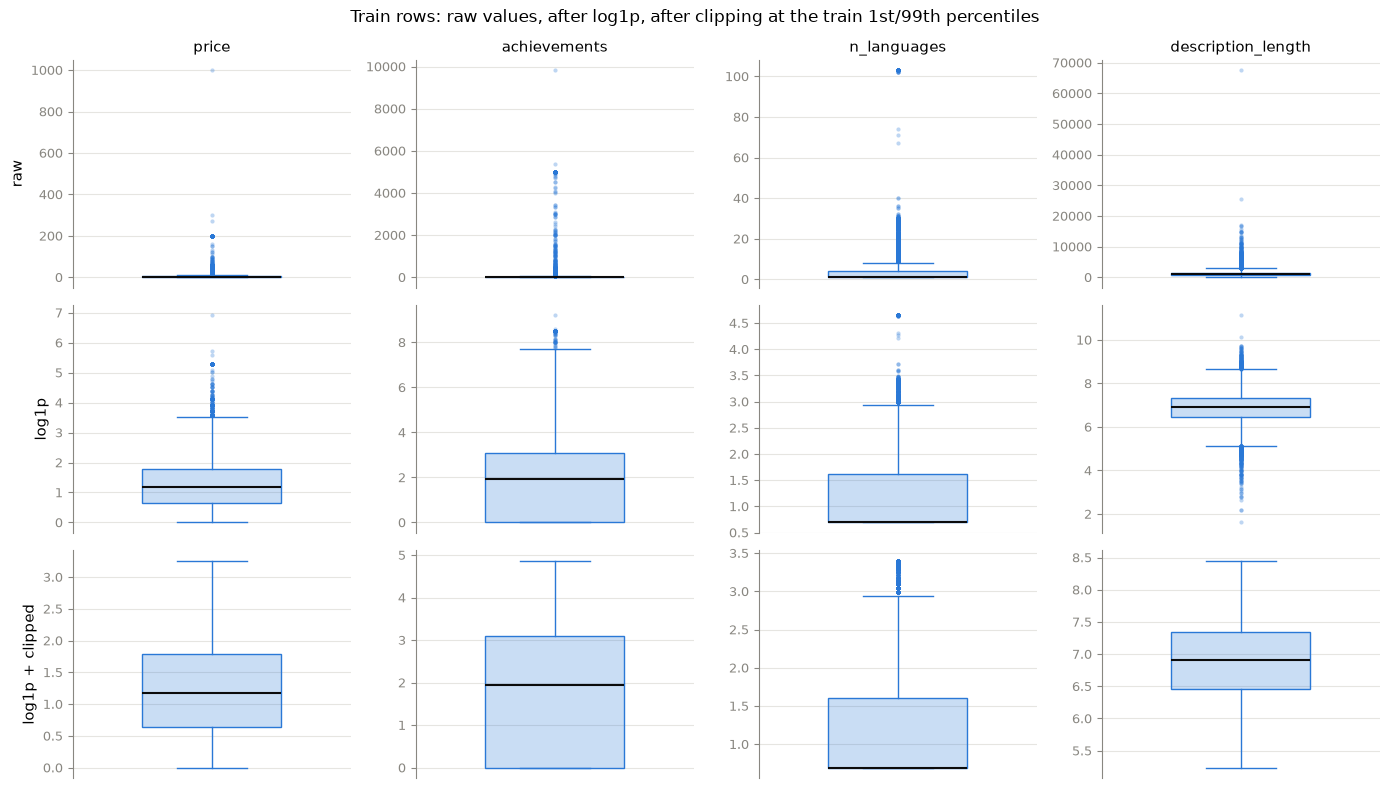

In [49]:
# Box plots, train rows: raw -> log1p -> log1p + clipped

# Quick note: generated with Claude (I wanted a nice readable plot and making one is annoying)

PLOT_COLS = ["price", "achievements", "n_languages", "description_length"]
stages = {
    "raw": lambda col: X_train[col],
    "log1p": lambda col: before_clip[f"log_{col}"],
    "log1p + clipped": lambda col: X_train[f"log_{col}"],
}
BLUE, INK, MUTED, GRID = "#2a78d6", "#0b0b0b", "#898781", "#e6e5e1"

fig, axes = plt.subplots(len(stages), len(PLOT_COLS), figsize=(14, 8))
for r, (stage, values) in enumerate(stages.items()):
    for c, col in enumerate(PLOT_COLS):
        ax = axes[r, c]
        ax.boxplot(values(col), widths=0.5, patch_artist=True,
                   boxprops=dict(facecolor=(0.165, 0.471, 0.839, 0.25), edgecolor=BLUE, linewidth=1),
                   whiskerprops=dict(color=BLUE, linewidth=1), capprops=dict(color=BLUE, linewidth=1),
                   medianprops=dict(color=INK, linewidth=1.5),
                   flierprops=dict(marker="o", markersize=3, markerfacecolor=BLUE, markeredgecolor="none", alpha=0.3))
        ax.set_xticks([])
        ax.yaxis.grid(True, color=GRID, linewidth=0.8)
        ax.set_axisbelow(True)
        ax.tick_params(colors=MUTED, labelsize=9)
        for side in ("top", "right", "bottom"):
            ax.spines[side].set_visible(False)
        ax.spines["left"].set_color(MUTED)
        if r == 0:
            ax.set_title(col, fontsize=11)
        if c == 0:
            ax.set_ylabel(stage, fontsize=11)
fig.suptitle("Train rows: raw values, after log1p, after clipping at the train 1st/99th percentiles", fontsize=12)
plt.tight_layout()
plt.show()

In [50]:
# Drop the raw versions
for col in LOG_COLS:
    DROP_LOG[col] = ("replaced by log", f"log_{col} (log1p + clipped) is used instead")
    KEEP_LOG.pop(col, None)
    FEATURES.pop(col, None)

X_train = X_train.drop(columns=LOG_COLS)
X_test = X_test.drop(columns=LOG_COLS)
print(f"train {X_train.shape}, test {X_test.shape}")

train (45491, 35), test (21760, 35)


Expected: no rows removed, 35 columns in both (41 - 6 raw columns), every clipped column inside the train caps in
train *and* test.

In [51]:
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)   # no rows removed
assert X_train.shape[1] == X_test.shape[1] == 35, (X_train.shape, X_test.shape)
assert not set(LOG_COLS) & set(X_train.columns)

for col in CLIP_COLS:
    low, high = caps.loc[col, "low"], caps.loc[col, "high"]
    assert X_train[col].between(low, high).all() and X_test[col].between(low, high).all(), col

print(f"train {X_train.shape}, test {X_test.shape}")

train (45491, 35), test (21760, 35)


## Step 10: Encode categoricals

- **Multi-label columns** (`genres`, `categories`, `supported_languages`) hold several labels per game, so one-hot
  becomes **multi-hot**: one 0/1 column per label (`genre_action`, `cat_single_player`, `lang_english`, ...).
  - The label list (vocabulary) is learned **on train only**: a label gets a column if at least `MIN_LABEL_COUNT` (50)
    train games have it. Test games get the same columns; a label never seen in train is ignored.
  - The cutoff keeps out near-empty columns, which hurt KNN (curse of dimensionality). Step 13 prunes more.
  - Steam Trading Cards is left out (`LEAKY_CATEGORIES`, step 4).
  - Gray area: "Family Sharing" is on 88% of games, including 2015 ones, so like languages it reflects the 2026 store.
- **Small categoricals** (`required_age`, `release_weekday`): `OneHotEncoder` fit on train. Ages with fewer than 50
  train games share one `required_age_rare` column.
- `developers`/`publishers` have tens of thousands of names, so no one-hot. Step 11 turns them into track-record numbers.
- `release_month` stays a number (1-12).

In [52]:
# Multi-hot: one 0/1 column per label, vocabulary learned on TRAIN only
MULTI_HOT = {"genres": "genre", "categories": "cat", "supported_languages": "lang"}

def label_dummies(s, col):
    # every family -> "label1|label2" -> one 0/1 column per label
    if col == "supported_languages":
        joined = s.str.findall(r"'([^']*)'").str.join("|")
    else:
        joined = s.str.replace(r"\s*,\s*", "|", regex=True)
    return joined.str.get_dummies(sep="|").astype(int).drop(columns=[""], errors="ignore")

VOCAB = {}
encoded_train, encoded_test = [], []
for col, prefix in MULTI_HOT.items():
    d_train = label_dummies(X_train[col], col)
    d_test = label_dummies(X_test[col], col)
    counts = d_train.sum()
    vocab = [label for label in counts.index
             if label and counts[label] >= MIN_LABEL_COUNT and label not in LEAKY_CATEGORIES]
    names = {label: f"{prefix}_{to_snake(label)}" for label in vocab}
    assert len(set(names.values())) == len(names), f"two {col} labels got the same column name"

    VOCAB[col] = vocab
    encoded_train.append(d_train[vocab].rename(columns=names))
    encoded_test.append(d_test.reindex(columns=vocab, fill_value=0).rename(columns=names))   # unseen labels ignored
    for label, name in names.items():
        FEATURES[name] = ("multi-hot", f"{col} includes '{label}'")
    print(f"{col}: {len(counts)} labels in train, {len(vocab)} kept (>= {MIN_LABEL_COUNT} train games)")

genres: 33 labels in train, 26 kept (>= 50 train games)
categories: 56 labels in train, 47 kept (>= 50 train games)
supported_languages: 103 labels in train, 103 kept (>= 50 train games)


In [53]:
# Which labels go with hits? (train rows; labels on at least 500 train games; 6 lowest and 8 highest)
multi_train = pd.concat(encoded_train, axis=1)
common = multi_train.columns[multi_train.sum() >= 500]
label_signal = pd.DataFrame({
    "train_games": multi_train[common].sum(),
    "hit_%_with": pd.Series({c: y_train[multi_train[c] == 1].mean() * 100 for c in common}),
    "hit_%_without": pd.Series({c: y_train[multi_train[c] == 0].mean() * 100 for c in common}),
})
label_signal["difference"] = label_signal["hit_%_with"] - label_signal["hit_%_without"]
label_signal.sort_values("difference").iloc[np.r_[0:6, -8:0]].round(1)

,train_games,hit_%_with,hit_%_without,difference
cat_family_sharing,39039,9.8,17.9,-8.1
cat_vr_only,3851,3.6,11.6,-8.0
cat_tracked_controller_support,4202,4.4,11.6,-7.2
cat_single_player,42749,10.5,17.5,-7.0
genre_casual,19427,7.2,13.6,-6.4
genre_early_access,4041,6.5,11.3,-4.9
lang_polish,4389,31.5,8.7,22.8
cat_custom_volume_controls,583,37.4,10.6,26.8
cat_steam_workshop,1280,37.0,10.2,26.9
cat_remote_play_on_tv,1603,39.2,9.9,29.3


In [54]:
# Small categoricals: OneHotEncoder fit on TRAIN; rare values share one column
SMALL_CATS = ["required_age", "release_weekday"]
onehot = OneHotEncoder(min_frequency=MIN_LABEL_COUNT, handle_unknown="infrequent_if_exist",
                       sparse_output=False).set_output(transform="pandas")
onehot.fit(X_train[SMALL_CATS])
oh_train = onehot.transform(X_train[SMALL_CATS]).astype(int)
oh_test = onehot.transform(X_test[SMALL_CATS]).astype(int)

oh_names = [name.replace("infrequent_sklearn", "rare") for name in oh_train.columns]
oh_train.columns = oh_names
oh_test.columns = oh_names
for name in oh_names:
    source, value = name.rsplit("_", 1)
    FEATURES[name] = ("one-hot", f"{source} is {value}")
print("one-hot columns:", oh_names)

one-hot columns: ['required_age_0', 'required_age_13', 'required_age_17', 'required_age_18', 'required_age_rare', 'release_weekday_0', 'release_weekday_1', 'release_weekday_2', 'release_weekday_3', 'release_weekday_4', 'release_weekday_5', 'release_weekday_6']


In [55]:
# Swap the text/categorical columns for their 0/1 columns
ENCODED = list(MULTI_HOT) + SMALL_CATS
X_train = pd.concat([X_train.drop(columns=ENCODED), *encoded_train, oh_train], axis=1)
X_test = pd.concat([X_test.drop(columns=ENCODED), *encoded_test, oh_test], axis=1)

for col in ENCODED:
    DROP_LOG[col] = ("encoded", "replaced by 0/1 columns in step 10")
    KEEP_LOG.pop(col, None)
    FEATURES.pop(col, None)
print(f"train {X_train.shape}, test {X_test.shape}")

train (45491, 218), test (21760, 218)


Expected: same rows, identical columns in train and test, every new column 0/1, no Steam Trading Cards column.

In [56]:
encoded_cols = [c for c in X_train.columns if FEATURES.get(c, ("",))[0] in ("multi-hot", "one-hot")]
assert len(encoded_cols) == sum(len(v) for v in VOCAB.values()) + len(oh_names)
assert list(X_train.columns) == list(X_test.columns)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
assert X_train[encoded_cols].isin([0, 1]).all().all() and X_test[encoded_cols].isin([0, 1]).all().all()
assert "cat_steam_trading_cards" not in X_train.columns

print(f"{len(encoded_cols)} encoded columns. train {X_train.shape}, test {X_test.shape}")

188 encoded columns. train (45491, 218), test (21760, 218)


## Step 11: Studio track record (developers and publishers)

Developers/publishers can't be one-hot encoded (tens of thousands of names), but who made the game* matters. So each
game gets its studio's track record on its release day:
- `dev_prior_games`: how many games its developer released before it (same-day releases don't count)
- `dev_prior_hits`: how many of those were hits
- `dev_hit_rate`: smoothed hit rate = (prior hits + 10 x train hit rate) / (prior labeled games + 10)
- the same three for the publisher (`pub_...`)
- a game with several developers (or publishers) takes the best number among them; the counts get log1p

Leakage rules:
1. Only games released strictly before count, so nothing from the future.
2. Only train labels count as hits. 
3. Gray area: "earlier hits" use 2026 owner counts, which weren't fully known on release day.


In [57]:
SMOOTHING = 10                 # a studio's record starts as if it had 10 average games
prior_rate = y_train.mean()    # the "average" hit rate, learned on train

def studio_history(frame, col, prefix, train_ids):
    # One row per (game, studio)
    rows = frame[["release_date", "hit"]].assign(studio=frame[col].str.split(",")).explode("studio")
    rows["studio"] = rows["studio"].str.strip()
    rows = rows[rows["studio"].notna() & rows["studio"].ne("")]
    rows["is_train"] = rows.index.isin(list(train_ids)).astype(int)
    rows["train_hit"] = rows["hit"] * rows["is_train"] 

    # Totals per studio per day
    daily = rows.groupby(["studio", "release_date"]).agg(
        games=("hit", "size"), train_games=("is_train", "sum"), train_hits=("train_hit", "sum"))
    before = daily.groupby(level="studio").cumsum() - daily
    rows = rows[["studio", "release_date"]].join(before, on=["studio", "release_date"])
    rows["rate"] = (rows["train_hits"] + SMOOTHING * prior_rate) / (rows["train_games"] + SMOOTHING)

    # One row per game
    per_game = rows.groupby(level=0)[["games", "train_hits", "rate"]].max().reindex(frame.index)
    return pd.DataFrame({
        f"{prefix}_prior_games": per_game["games"].fillna(0),
        f"{prefix}_prior_hits": per_game["train_hits"].fillna(0),
        f"{prefix}_hit_rate": per_game["rate"].fillna(prior_rate),
    })

In [58]:
# History for every game in the window (train + test), from df
train_ids = set(X_train.index)
history_raw = pd.concat([studio_history(df, "developers", "dev", train_ids), studio_history(df, "publishers", "pub", train_ids)], axis=1)

# Leak check: flip every test label -> no feature may change
flipped = df.assign(hit=df["hit"].where(~df.index.isin(X_test.index), 1 - df["hit"]))
assert studio_history(flipped, "developers", "dev", train_ids).equals(history_raw.filter(like="dev_"))
assert studio_history(flipped, "publishers", "pub", train_ids).equals(history_raw.filter(like="pub_"))
print("Leak check pass")


def by_bucket(col):
    bucket = pd.cut(history_raw.loc[X_train.index, col], [-1, 0, 1, 4, np.inf], labels=["0", "1", "2-4", "5+"])
    return y_train.groupby(bucket, observed=True).agg(train_games="size", hit_pct=lambda s: s.mean() * 100)
pd.concat({"developer's earlier hits": by_bucket("dev_prior_hits"), "publisher's earlier hits": by_bucket("pub_prior_hits")}, axis=1).round(1)

Leak check pass


developer's earlier hits         publisher's earlier hits        
                 train_games hit_pct              train_games hit_pct
0                      39909     8.6                    36756     7.0
1                       2705    25.1                     2897    19.3
2-4                     1539    33.8                     2216    30.2
5+                      1338    25.7                     3622    31.7

In [59]:
# log1p the counts, attach to train/test, drop the columns that are now used up
history = history_raw.copy()
for col in ["dev_prior_games", "dev_prior_hits", "pub_prior_games", "pub_prior_hits"]:
    history[f"log_{col}"] = np.log1p(history.pop(col))

X_train = X_train.join(history)
X_test = X_test.join(history)

for who, name in (("dev", "developer"), ("pub", "publisher")):
    FEATURES.update({
        f"log_{who}_prior_games": ("history", f"log1p of the {name}'s games released strictly before this one"),
        f"log_{who}_prior_hits": ("history", f"log1p of how many of those were hits (train labels only)"),
        f"{who}_hit_rate": ("history", f"smoothed hit rate of the {name}'s earlier games (train labels only)"),
    })

for col in ["developers", "publishers", "release_date"]:
    DROP_LOG[col] = ("turned into features", "used up by the step 11 studio history")
    KEEP_LOG.pop(col, None)
X_train = X_train.drop(columns=["developers", "publishers", "release_date"])
X_test = X_test.drop(columns=["developers", "publishers", "release_date"])

history_cols = list(history.columns)
pd.Series({col: roc_auc_score(y_train, X_train[col]) for col in history_cols}, name="train_auc_vs_hit").to_frame()

,train_auc_vs_hit
dev_hit_rate,0.675491
pub_hit_rate,0.723853
log_dev_prior_games,0.510704
log_dev_prior_hits,0.605980
log_pub_prior_games,0.576998
log_pub_prior_hits,0.666618


Expected: 6 history columns, no NaN, same columns in train and test, and the leak check above passed.

In [60]:
assert len(history_cols) == 6
assert X_train[history_cols].notna().all().all() and X_test[history_cols].notna().all().all()
assert list(X_train.columns) == list(X_test.columns)
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index)
print(f"train {X_train.shape}, test {X_test.shape}")

train (45491, 221), test (21760, 221)


## Step 12: Text features 

The rubric asks for text vectorization where it applies: `about_the_game` is the store description.
1. Clean: strip HTML bits
2. TF-IDF (`TfidfVectorizer`): each description becomes a vector of word and 2-word-phrase weights. A term weighs the most when it's common in this description but rare across all of them. English stop words removed, terms in fewer than 5 descriptions ignored, top 20000 terms kept.
3. 20,,000 mostly-empty columns would swamp the other features (and KNN), so a logistic regression on the TF-IDF squeezes the text into one number: `text_score`, the predicted chance of a hit from the description alone.
   - Train rows get out-of-fold scores (`cross_val_predict`, 5 folds): each train game is scored by a model that never saw it.
   - Test rows are scored by the model fit on all of train.
   - This is stacking (I WISH I DID THIS BEFORE THE EXAM) one model's prediction becomes a feature for the next.

In [61]:
def clean_text(s):
    return s.str.replace(r"<[^>]+>|&\w+;", " ", regex=True)   # HTML tags and entities -> space

text_train = clean_text(X_train["about_the_game"])
text_test = clean_text(X_test["about_the_game"])

text_model = make_pipeline(
    TfidfVectorizer(stop_words="english", ngram_range=(1, 2), min_df=5, max_features=20_000, sublinear_tf=True),
    LogisticRegression(max_iter=1000, class_weight="balanced"),
)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

X_train["text_score"] = cross_val_predict(text_model, text_train, y_train, cv=folds, method="predict_proba", n_jobs=-1)[:, 1]
text_model.fit(text_train, y_train)
X_test["text_score"] = text_model.predict_proba(text_test)[:, 1]

FEATURES["text_score"] = ("text", "hit probability from the description alone (TF-IDF + logistic regression; out-of-fold on train)")
print(f"TF-IDF vocabulary: {len(text_model[0].vocabulary_)} terms")
print(f"text alone, PR-AUC: train (out-of-fold) {average_precision_score(y_train, X_train['text_score'])}, "
      f"test {average_precision_score(y_test, X_test['text_score'])}  (no skill: {y_train.mean()} / {y_test.mean()})")

TF-IDF vocabulary: 20000 terms
text alone, PR-AUC: train (out-of-fold) 0.36228188203319917, test 0.23799448536982595  (no skill: 0.10909850300059352 / 0.05620404411764706)


In [62]:
# Which words push the text score up or down? (model fit on all of train)
terms = text_model[0].get_feature_names_out()
order = np.argsort(text_model[-1].coef_[0])
pd.DataFrame({"towards hit": terms[order[::-1][:15]], "towards not hit": terms[order[:15]]})

,towards hit,towards not hit
0,free play,vr
1,community,ideas
2,online,virtual reality
3,idle,luck
4,free,scenes
5,creators,local multiplayer
6,trading cards,collecting
7,op,add
8,expand,collector
9,acclaimed,early access


In [63]:
DROP_LOG["about_the_game"] = ("turned into features", "used up by the step 12 text_score")
KEEP_LOG.pop("about_the_game", None)
X_train = X_train.drop(columns="about_the_game")
X_test = X_test.drop(columns="about_the_game")

Expected: `text_score` between 0 and 1 with no NaN, `about_the_game` gone.

In [64]:
for part in (X_train, X_test):
    assert part["text_score"].between(0, 1).all() and part["text_score"].notna().all()
    assert "about_the_game" not in part.columns
assert list(X_train.columns) == list(X_test.columns)
print(f"train {X_train.shape}, test {X_test.shape}")

train (45491, 221), test (21760, 221)


## Step 13: Feature selection



For feature selection we will be using filter ensemble methods, this is so that all algorithms will use the same features and feature selection will not need to be done for each model.

Since our current features are catagorical and numerical the best filter method to use is the peason coefficient.

Fetaures under the variance level will eliminated from the training and testing set

In [65]:
# Calculate correlation scores for X_test
correlation_scores = X_test.corrwith(y_test, numeric_only=True)

# Sort values and take the top 25 correlated features
top_features = correlation_scores.abs().sort_values(ascending=False).head(25)

# Display the top 25 correclated features
print("Top Features:")
print(top_features.index.tolist())

C:\Users\Semyon Baykov\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3023: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
C:\Users\Semyon Baykov\anaconda3\Lib\site-packages\numpy\lib\_function_base_impl.py:3024: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


Top Features:
['pub_hit_rate', 'text_score', 'log_pub_prior_hits', 'dev_hit_rate', 'n_categories', 'log_n_languages', 'lang_portuguese_brazil', 'lang_german', 'lang_french', 'log_achievements', 'lang_simplified_chinese', 'lang_spanish_spain', 'lang_italian', 'lang_korean', 'cat_steam_cloud', 'lang_polish', 'lang_traditional_chinese', 'lang_japanese', 'lang_russian', 'required_age_0', 'required_age_17', 'log_dev_prior_hits', 'cat_surround_sound', 'cat_online_co_op', 'cat_steam_achievements']


In [66]:
# Remove nonsubstantial features from training set 
X_train = X_train[top_features.index]

# Remove nonsubstantial features from testing set
X_test = X_test[top_features.index]

## 14. Class imbalance

*To do.* Plot classes per split; SMOTE variant on train only.

In [67]:
from imblearn.over_sampling import SMOTE

smote = SMOTE(sampling_strategy='minority', random_state=42)
X_train, y_train = smote.fit_resample(X_train, y_train)

## 15. Scaling
to do
Used standard scaler because 
it handles features with different units effectively.
It reduces impact of outliers without completely removing them.

In [68]:
from sklearn.preprocessing import StandardScaler
# Scale all features to between 0 and 1
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.fit_transform(X_test)
print('done')

done


In [69]:
# X_train = pd.DataFrame(X_train)
# X_test = pd.DataFrame(X_test)
# y_train = pd.DataFrame(y_train)
# y_test = pd.DataFrame(y_test)
# X_train = X_train.reset_index(drop=True)
# y_train = y_train.reset_index(drop=True)
# X_test = X_test.reset_index(drop=True)
# y_test = y_test.reset_index(drop=True)


## Step 16: Final checks and save

`name` was only kept for the duplicate check (step 5) and the outlier examples (step 9). It's text, so it's dropped here.

Files written to `data/processed/` (gitignored, so run this notebook to regenerate them):

| File | Contents |
| --- | --- |
| `X_train.csv`, `X_test.csv` | features: all numeric, no NaN, same column order |
| `y_train.csv`, `y_test.csv` | one column `hit` (0/1), same row order as X |
| `feature_names.json` | each column's family and meaning, every dropped column with its reason, and the config used |

In [70]:
# name was only needed for the duplicate check and the outlier examples
DROP_LOG["name"] = ("irrelevant", "game title: used for the duplicate check, not a feature")
KEEP_LOG.pop("name", None)
X_train = X_train.drop(columns="name")
X_test = X_test.drop(columns="name")
print(f"train {X_train.shape}, test {X_test.shape}")

AttributeError: 'numpy.ndarray' object has no attribute 'drop'

In [ ]:
# Last checks before anything is written
assert list(X_train.columns) == list(X_test.columns), "train and test columns differ"
assert X_train.index.equals(y_train.index) and X_test.index.equals(y_test.index), "X and y rows don't line up"
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, "NaN left"
non_numeric = [col for col in X_train.columns if not pd.api.types.is_numeric_dtype(X_train[col])]
assert not non_numeric, non_numeric
assert not set(DROP_LOG) & set(X_train.columns), "a dropped column is still there"
assert TARGET not in X_train.columns
undocumented = [col for col in X_train.columns if col not in FEATURES]
assert not undocumented, undocumented

print(f"All checks passed: train {X_train.shape}, test {X_test.shape}")
print(f"hits: train {y_train.mean()}, test {y_test.mean()}")

# What the modelers get, by feature family
pd.Series({col: FEATURES[col][0] for col in X_train.columns}).value_counts().rename("columns").to_frame()

In [ ]:
OUT_DIR.mkdir(parents=True, exist_ok=True)
X_train.to_csv(OUT_DIR / "X_train.csv", index=False)
X_test.to_csv(OUT_DIR / "X_test.csv", index=False)
y_train.to_frame(TARGET).to_csv(OUT_DIR / "y_train.csv", index=False)
y_test.to_frame(TARGET).to_csv(OUT_DIR / "y_test.csv", index=False)

feature_info = {
    "config": {"hit_threshold": HIT_THRESHOLD, "years": [YEAR_MIN, YEAR_MAX], "split": SPLIT,
               "test_years": list(TEST_YEARS), "random_state": RANDOM_STATE},
    "columns": [{"name": col, "family": FEATURES[col][0], "meaning": FEATURES[col][1]} for col in X_train.columns],
    "dropped": {col: {"group": group, "reason": reason} for col, (group, reason) in DROP_LOG.items()},
}
with open(OUT_DIR / "feature_names.json", "w", encoding="utf-8") as f:
    json.dump(feature_info, f, indent=1, ensure_ascii=False)

print("Saved to", OUT_DIR.resolve())

In [ ]:
# Read the files back the way a teammate would and check they match
X_train_check = pd.read_csv(OUT_DIR / "X_train.csv")
X_test_check = pd.read_csv(OUT_DIR / "X_test.csv")
y_train_check = pd.read_csv(OUT_DIR / "y_train.csv")["hit"]
y_test_check = pd.read_csv(OUT_DIR / "y_test.csv")["hit"]

assert X_train_check.shape == X_train.shape and X_test_check.shape == X_test.shape
assert list(X_train_check.columns) == list(X_train.columns)
assert (y_train_check.to_numpy() == y_train.to_numpy()).all() and (y_test_check.to_numpy() == y_test.to_numpy()).all()

for path in sorted(OUT_DIR.iterdir()):
    print(f"{path.name:20} {path.stat().st_size / 1e6:6.1f} MB") 
    # https://stackoverflow.com/questions/12523586/python-format-size-application-converting-b-to-kb-mb-gb-tb

### How to load (for the modelers)

```python
import pandas as pd
P = "../data/processed/"   # path from your notebook's folder to project-repo.git/data/processed
X_train = pd.read_csv(P + "X_train.csv"); X_test = pd.read_csv(P + "X_test.csv")
y_train = pd.read_csv(P + "y_train.csv")["hit"]; y_test = pd.read_csv(P + "y_test.csv")["hit"]
```